In [1]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from forecast_utils import summarize
from study_config import *

assert "MAPE" in inspect.getsource(summarize), \
    "Replace forecast_utils.py with the MAPE version, then restart the kernel."
print("forecast_utils.py includes MAPE: OK")

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

forecast_utils.py includes MAPE: OK


In [2]:
retail = (pd.read_csv(PROC / "wfp_retail_tagged.csv", parse_dates=["date"])
            .drop(columns=["period"], errors="ignore"))
retail["ym"] = retail["date"].dt.to_period("M")
retail["period"] = retail["ym"].map(period_label)

print("Retail rows by period:\n", retail["period"].value_counts())
print("\nRetail inventory:", retail.nunique()[["commodity", "category", "market_id", "admin1"]].to_dict())
print("\nCommodities per category:\n", retail.groupby("category")["commodity"].nunique())

Retail rows by period:
 period
Pandemic         104527
Post-pandemic     94566
Pre-pandemic       8508
Excluded            123
Name: count, dtype: int64

Retail inventory: {'commodity': 64, 'category': 4, 'market_id': 97, 'admin1': 17}

Commodities per category:
 category
cereals and tubers       12
meat, fish and eggs      22
pulses and nuts           3
vegetables and fruits    27
Name: commodity, dtype: int64


In [3]:
d = retail[retail["period"] != "Excluded"].copy()
d["mnum"] = (d["date"].dt.year - 2016) * 12 + d["date"].dt.month - 1
d = d.sort_values(["market_id", "commodity_id", "date"])
d["log_price"] = np.log(d["price"])

g = d.groupby(["market_id", "commodity_id"])
d["lr"] = g["log_price"].diff()
d["gap"] = g["mnum"].diff()
d.loc[d["gap"] != 1, "lr"] = np.nan              # only true consecutive months; never across a gap
d["flag_jump"] = d["lr"].abs() > JUMP
d["segment"] = np.where(d["period"] == "Pre-pandemic", "A", "B")

n_ret, n_flag = int(d["lr"].notna().sum()), int(d["flag_jump"].sum())
print(f"Series: {g.ngroups} | valid monthly changes: {n_ret} | flagged: {n_flag} ({n_flag / n_ret * 100:.2f}%)")
core_flags = int(d[d["commodity"].isin(CORE)]["flag_jump"].sum())
print("Core-5 flags (should equal Step 4's 111):", core_flags, "| other commodities:", n_flag - core_flags)

Series: 4589 | valid monthly changes: 201964 | flagged: 1721 (0.85%)
Core-5 flags (should equal Step 4's 111): 111 | other commodities: 1610


In [4]:
flags = d[d["flag_jump"]]
flags.to_csv(TAB / "09_flagged_jumps_all.csv", index=False)

print("Flags by category:\n", flags.groupby("category").size())

rate = d.groupby("commodity").agg(n_returns=("lr", "count"), n_flags=("flag_jump", "sum"))
rate["flag_rate_pct"] = (rate["n_flags"] / rate["n_returns"] * 100).round(2)
rate.to_csv(TAB / "09_flag_rate_by_commodity.csv")
display(rate.sort_values("n_flags", ascending=False).head(10))
print("Commodities with at least one flag:", int((rate["n_flags"] > 0).sum()), "of", len(rate))

per = d.groupby("period").agg(n_returns=("lr", "count"), n_flags=("flag_jump", "sum"))
per["rate_pct"] = (per["n_flags"] / per["n_returns"] * 100).round(2)
display(per)
print("Flags by year:", flags.groupby(flags["date"].dt.year).size().to_dict())

Flags by category:
 category
cereals and tubers         16
meat, fish and eggs        52
pulses and nuts             5
vegetables and fruits    1648
dtype: int64


,n_returns,n_flags,flag_rate_pct
commodity,,,
Tomatoes,5927,501,8.45
Eggplants,5786,158,2.73
Cabbage,5645,154,2.73
Onions (red),5316,110,2.07
Carrots,5919,109,1.84
"Beans (green, fresh)",2869,105,3.66
Bitter melon,5459,91,1.67
Beans (string),3418,82,2.40
Choko,4124,65,1.58


Commodities with at least one flag: 42 of 64


,n_returns,n_flags,rate_pct
period,,,
Pandemic,99426,963,0.97
Post-pandemic,94422,698,0.74
Pre-pandemic,8116,60,0.74


Flags by year: {2016: 10, 2017: 21, 2018: 21, 2019: 8, 2020: 356, 2021: 325, 2022: 168, 2023: 242, 2024: 217, 2025: 259, 2026: 94}


In [5]:
d["n_series"] = d.groupby(["market_id", "commodity_id"])["price"].transform("size")
elig = d[d["n_series"] >= MIN_MONTHS_TREND]

rows = []
for (m, c), s in elig.groupby(["market_id", "commodity_id"]):
    slope = np.polyfit(s["mnum"].to_numpy(float), s["log_price"].to_numpy(), 1)[0] * 12
    lr = s["lr"].dropna()
    rows.append({"market_id": m, "commodity_id": c, "category": s["category"].iloc[0],
                 "commodity": s["commodity"].iloc[0], "admin1": s["admin1"].iloc[0],
                 "market": s["market"].iloc[0], "n_obs": len(s), "n_returns": len(lr),
                 "trend_pct_yr": (np.exp(slope) - 1) * 100,
                 "vol_pct": lr.std() * 100 if len(lr) >= MIN_RETURNS_VOL else np.nan})
S = pd.DataFrame(rows)
S.to_csv(TAB / "09_series_stats.csv", index=False)
print(f"Eligible series: {len(S)} | commodities: {S['commodity'].nunique()} | "
      f"markets: {S['market_id'].nunique()} | regions: {S['admin1'].nunique()}")

agg = lambda by: S.groupby(by).agg(series=("n_obs", "size"),
                                   trend_pct_yr=("trend_pct_yr", "median"),
                                   vol_pct=("vol_pct", "median")).round(2)
by_cat, by_com = agg("category"), agg(["category", "commodity"])
by_reg, by_mkt = agg("admin1"), agg(["admin1", "market"])
for name, t in [("category", by_cat), ("commodity", by_com), ("region", by_reg), ("market", by_mkt)]:
    t.to_csv(TAB / f"09_trend_vol_by_{name}.csv")

display(by_cat)
bc = by_com[by_com["series"] >= 5]       # commodities with at least 5 series
print(f"Commodities with >= 5 series: {len(bc)} of {len(by_com)}")
print("\nSteepest trend:");  display(bc.sort_values("trend_pct_yr", ascending=False).head(5))
print("Flattest trend:");   display(bc.sort_values("trend_pct_yr").head(5))
print("Most volatile:");    display(bc.sort_values("vol_pct", ascending=False).head(5))
print("Least volatile:");   display(bc.sort_values("vol_pct").head(3))
print("Regions, highest trend:"); display(by_reg.sort_values("trend_pct_yr", ascending=False).head(3))
print("Regions, lowest trend:");  display(by_reg.sort_values("trend_pct_yr").head(3))
print("Retail commodities with no eligible series:", sorted(set(retail["commodity"]) - set(S["commodity"])))

Eligible series: 2725 | commodities: 61 | markets: 97 | regions: 17


,series,trend_pct_yr,vol_pct
category,,,
cereals and tubers,415,5.01,3.98
"meat, fish and eggs",981,5.60,4.08
pulses and nuts,122,3.45,3.96
vegetables and fruits,1207,7.05,12.96


Commodities with >= 5 series: 58 of 61

Steepest trend:


series  trend_pct_yr  vol_pct
category              commodity                                          
meat, fish and eggs   Fish (fresh)              14         12.24     4.63
vegetables and fruits Beans (green, fresh)      36         10.84    19.65
                      Beans (string)            43         10.81    15.16
                      Choko                     51         10.75    16.88
                      Carrots                   84         10.34    18.02

Flattest trend:


series  trend_pct_yr  vol_pct
category              commodity                                             
vegetables and fruits Onions (white)               17          1.80    13.59
meat, fish and eggs   Shrimp (endeavor)            17          2.26     4.65
                      Shrimp (tiger)               56          2.46     5.97
cereals and tubers    Rice (milled, superior)       6          2.79     1.61
meat, fish and eggs   Fish (frigate tuna)           7          2.83     8.17

... (5 outputs left out)

,series,trend_pct_yr,vol_pct
admin1,,,
National Capital region,45,7.01,3.88
Region X,162,6.86,5.95
Region XI,164,6.53,6.72


Regions, lowest trend:


,series,trend_pct_yr,vol_pct
admin1,,,
Autonomous region in Muslim Mindanao,123,3.74,6.14
Region VII,130,5.06,7.87
Region IV-A,172,5.08,5.48


Retail commodities with no eligible series: ['Chicken', 'Maize (white)', 'Rice (premium)']


In [6]:
def chain(dd, by, base_month):
    m = dd[dd["lr"].notna()].groupby([by, "ym"])["lr"].mean().unstack(by)
    start = pd.DataFrame(0.0, index=[base_month], columns=m.columns)     # base month = 100
    m = pd.concat([start, m.fillna(0)]).sort_index()
    return 100 * np.exp(m.cumsum())

cA = chain(d[d["segment"] == "A"], "category", PRE_START)
cB = chain(d[d["segment"] == "B"], "category", PAN_START)
cR = chain(d[d["segment"] == "B"], "admin1", PAN_START)

print("Segment A (Jan 2016 = 100):"); display(cA.iloc[[0, -1]].round(1))
print("Segment B (May 2020 = 100):"); display(cB.iloc[[0, -1]].round(1))
for seg in ["A", "B"]:
    n = d[(d["segment"] == seg) & d["lr"].notna()].groupby("ym").size()
    print(f"Monthly changes behind the index, Segment {seg}: min {n.min()}, max {n.max()}")
print("Regions, highest end value:", cR.iloc[-1].round(1).sort_values(ascending=False).head(3).to_dict())
print("Regions, lowest end value:", cR.iloc[-1].round(1).sort_values().head(3).to_dict())
print("Regional index shape (months x regions):", cR.shape)

cA.to_csv(TAB / "09_chain_index_category_A.csv")
pd.concat([cB.add_prefix("cat: "), cR.add_prefix("reg: ")], axis=1).to_csv(TAB / "09_chain_index_B.csv")

Segment A (Jan 2016 = 100):


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
2016-01,100.0,100.0,100.0,100.0
2019-05,109.3,115.1,95.6,82.5


Segment B (May 2020 = 100):


category,cereals and tubers,"meat, fish and eggs",pulses and nuts,vegetables and fruits
2020-05,100.0,100.0,100.0,100.0
2026-06,131.3,140.4,130.9,134.9


Monthly changes behind the index, Segment A: min 137, max 245
Monthly changes behind the index, Segment B: min 2176, max 3853
Regions, highest end value: {'Region V': 145.8, 'Region X': 144.8, 'Region XII': 144.7}
Regions, lowest end value: {'Autonomous region in Muslim Mindanao': 119.1, 'Cordillera Administrative region': 127.2, 'Region IV-A': 130.0}
Regional index shape (months x regions): (74, 17)


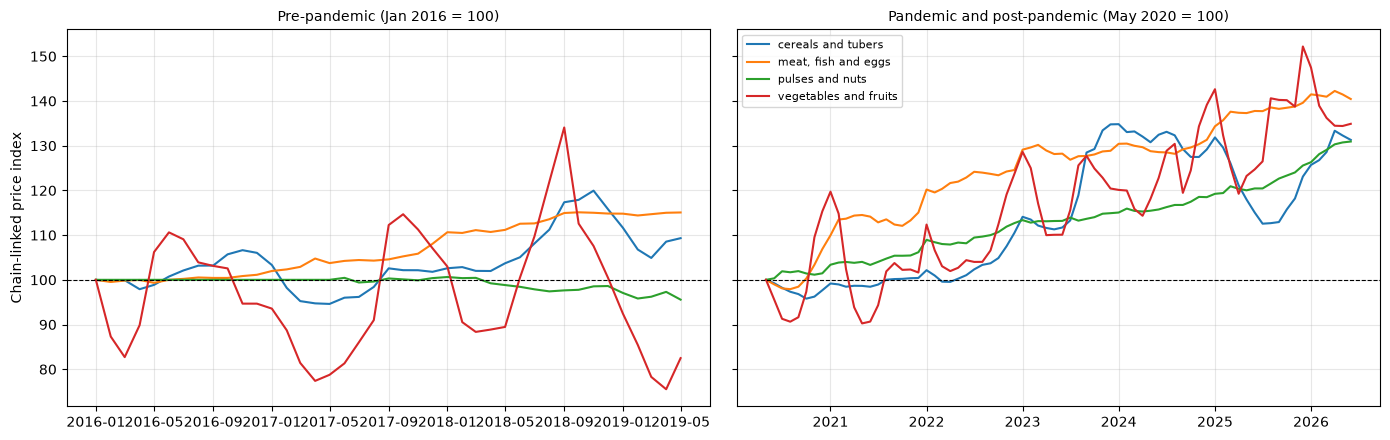

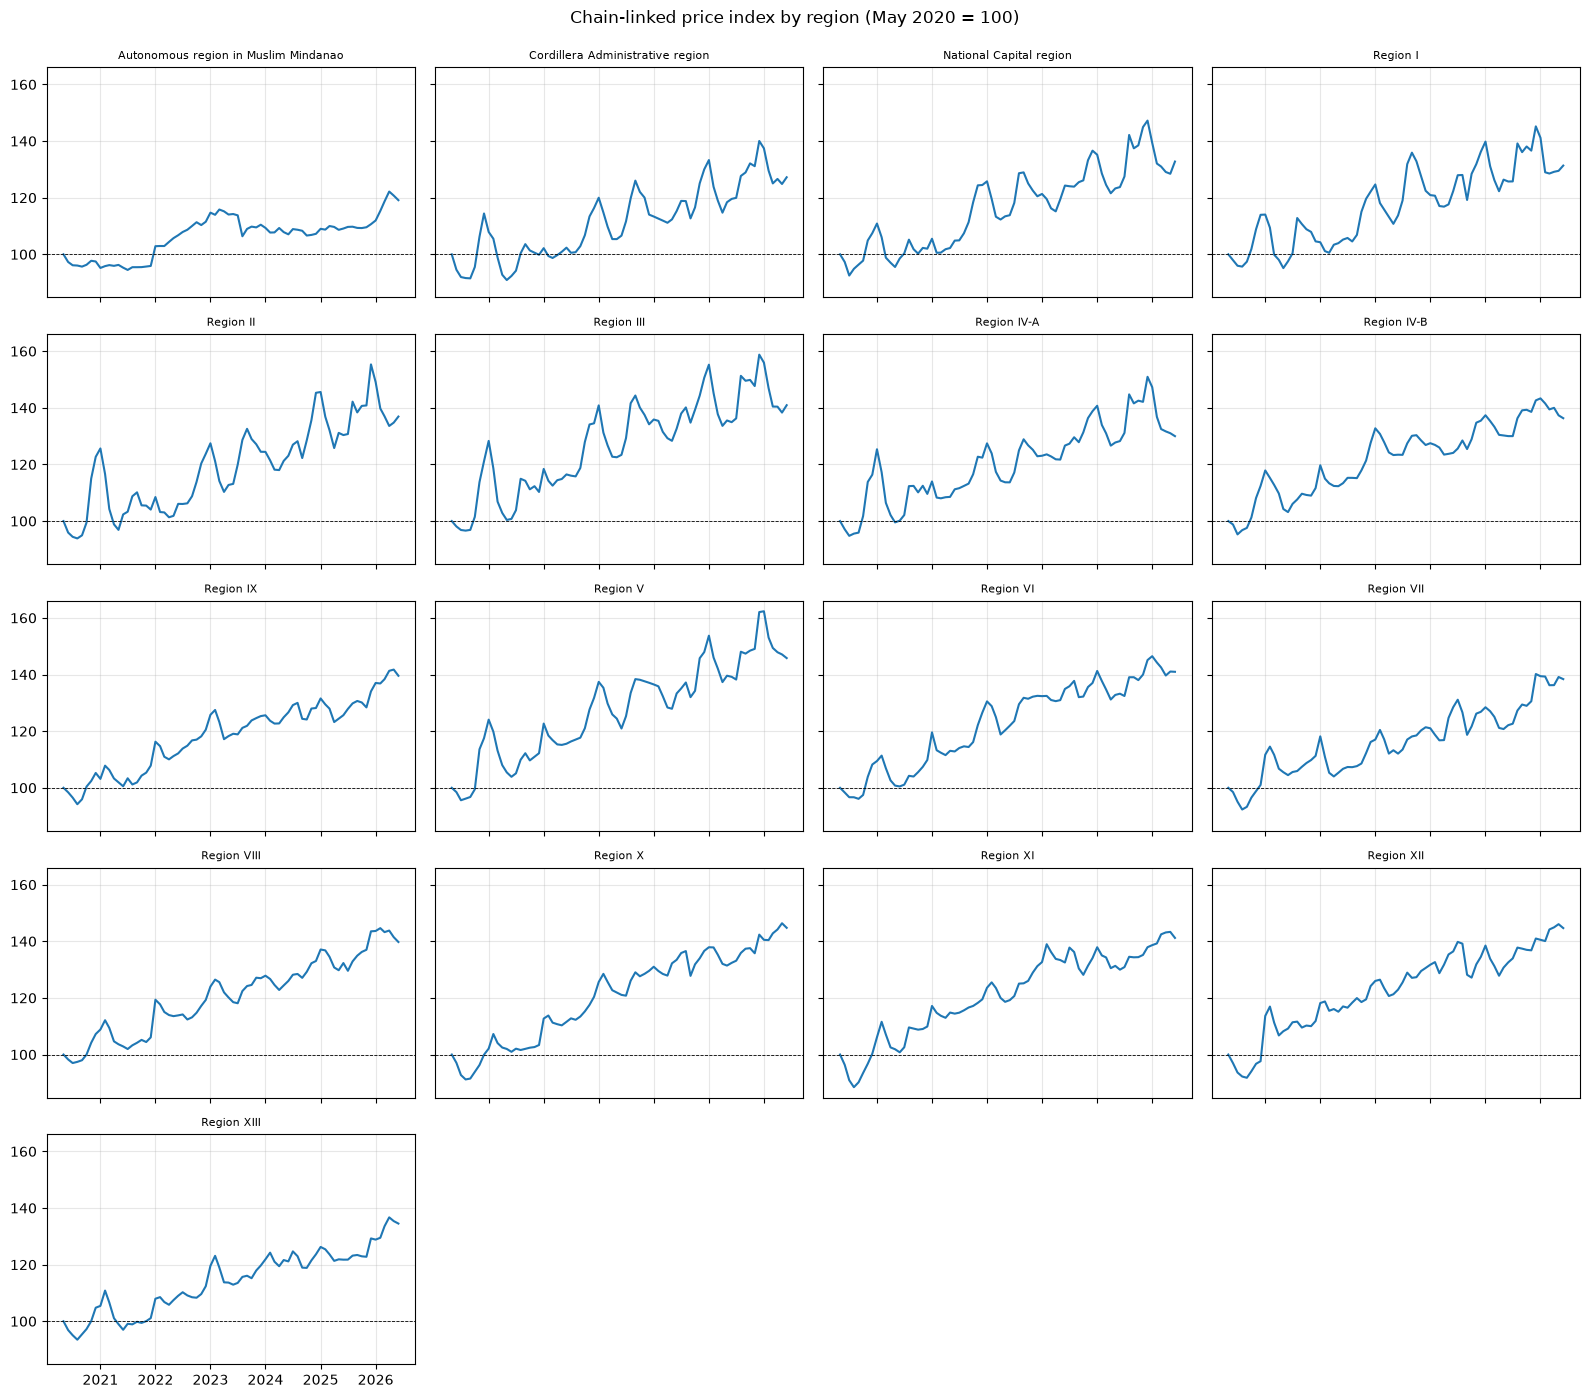

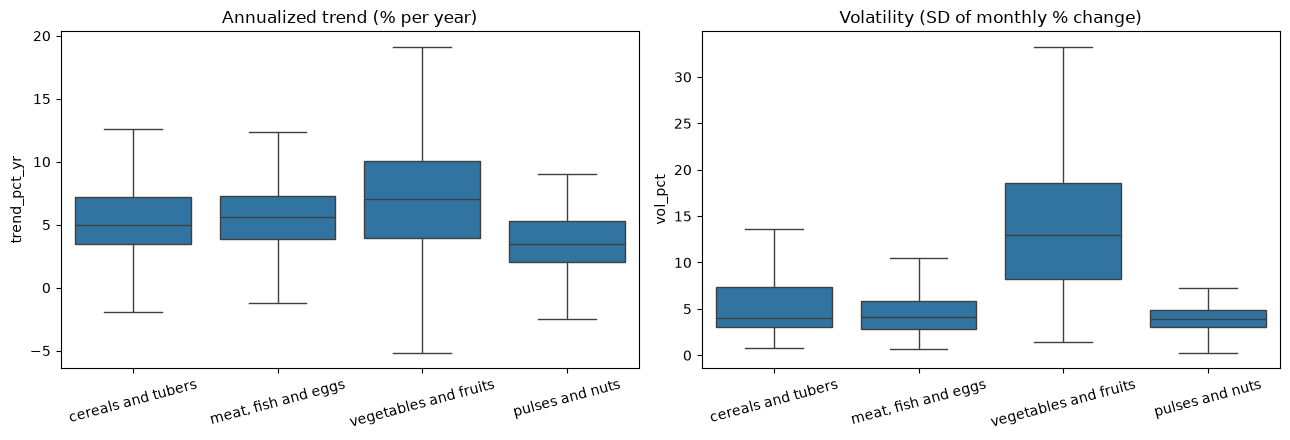

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, idx) in zip(axes, [("Pre-pandemic (Jan 2016 = 100)", cA),
                                   ("Pandemic and post-pandemic (May 2020 = 100)", cB)]):
    x = idx.index.to_timestamp()
    for col in idx.columns:
        ax.plot(x, idx[col], label=col)
    ax.axhline(100, color="black", lw=0.8, ls="--"); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
axes[0].set_ylabel("Chain-linked price index"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "09_chain_category.png", dpi=150); plt.show()

fig, axes = plt.subplots(5, 4, figsize=(16, 14), sharex=True, sharey=True)
for ax, reg in zip(axes.ravel(), cR.columns):
    ax.plot(cR.index.to_timestamp(), cR[reg]); ax.axhline(100, color="black", lw=0.6, ls="--")
    ax.set_title(reg, fontsize=8); ax.grid(alpha=0.3)
for ax in axes.ravel()[len(cR.columns):]:
    ax.axis("off")
plt.suptitle("Chain-linked price index by region (May 2020 = 100)", y=0.995)
plt.tight_layout(); plt.savefig(FIG / "09_chain_region.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=S, x="category", y="trend_pct_yr", showfliers=False, ax=axes[0]); axes[0].set_title("Annualized trend (% per year)")
sns.boxplot(data=S, x="category", y="vol_pct", showfliers=False, ax=axes[1]); axes[1].set_title("Volatility (SD of monthly % change)")
for ax in axes:
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(FIG / "09_trend_vol_by_category.png", dpi=150); plt.show()

In [8]:
out = d[["date", "period", "segment", "admin1", "admin2", "market_id", "market", "category",
         "commodity_id", "commodity", "unit", "price", "log_price", "lr", "flag_jump"]].copy()
out.to_csv(PROC / "retail_clean_flagged.csv", index=False)
print(out.shape)

(207601, 15)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from study_config import *

RAW = Path("../data/raw")
PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

retail = (pd.read_csv(PROC / "wfp_retail_tagged.csv", parse_dates=["date"])
            .drop(columns=["period"], errors="ignore"))
retail["ym"] = retail["date"].dt.to_period("M")
retail["period"] = retail["ym"].map(period_label)

S = pd.read_csv(TAB / "09_series_stats.csv")
markets_file = pd.read_csv(RAW / "wfp_markets_phl.csv")

In [2]:
base = (retail.groupby(["commodity", "category", "unit"])
        .agg(observations=("price", "size"), markets=("market_id", "nunique"),
             first_month=("ym", "min"), last_month=("ym", "max"),
             min_price=("price", "min"), median_price=("price", "median"),
             max_price=("price", "max")).reset_index())

per = retail.pivot_table(index="commodity", columns="period", values="price",
                         aggfunc="size", fill_value=0)
per = per.reindex(columns=["Pre-pandemic", "Pandemic", "Post-pandemic", "Excluded"], fill_value=0)
base = base.merge(per.add_prefix("obs_").reset_index(), on="commodity")

ms = (retail[retail["period"] != "Excluded"].groupby(["commodity", "market_id"])
        .size().rename("months").reset_index())
ser = ms.groupby("commodity").agg(series=("months", "size"),
                                  longest_series_months=("months", "max"),
                                  eligible_series=("months", lambda x: (x >= MIN_MONTHS_TREND).sum())).reset_index()

cov = base.merge(ser, on="commodity")
cov["first_month"], cov["last_month"] = cov["first_month"].astype(str), cov["last_month"].astype(str)
cov["tier"] = pd.cut(cov["eligible_series"], [-1, 0, 4, 10**6],
                     labels=["none (0)", "limited (1-4)", "adequate (5+)"])

print("Commodities by data tier:", cov["tier"].value_counts().to_dict(), "| total:", len(cov))
miss = cov[cov["eligible_series"] == 0].round(1)
display(miss.drop(columns="tier").T)
print("Limited tier:")
display(cov[cov["eligible_series"].between(1, 4)][["commodity", "category", "eligible_series"]])

cov.to_csv(TAB / "09B_commodity_coverage.csv", index=False)
miss.to_csv(TAB / "09B_missing_commodities.csv", index=False)

Commodities by data tier: {'adequate (5+)': 58, 'none (0)': 3, 'limited (1-4)': 3} | total: 64


,13,33,50
commodity,Chicken,Maize (white),Rice (premium)
category,"meat, fish and eggs",cereals and tubers,cereals and tubers
unit,KG,KG,KG
observations,68,83,471
markets,9,11,63
first_month,2020-05,2020-05,2020-05
last_month,2020-12,2022-04,2020-12
min_price,64.4,18.0,33.4
median_price,130.0,28.0,45.6
max_price,180.0,50.0,53.4


Limited tier:


,commodity,category,eligible_series
37,Mangoes (piko),vegetables and fruits,4
42,"Meat (pork, hock)","meat, fish and eggs",4
46,Papaya,vegetables and fruits,4


In [3]:
mk = (retail.groupby(["market_id", "market", "admin1", "admin2"])
      .agg(latitude=("latitude", "first"), longitude=("longitude", "first"),
           n_coords=("latitude", "nunique"), observations=("price", "size"),
           commodities=("commodity", "nunique"), months_active=("ym", "nunique"),
           first_month=("ym", "min"), last_month=("ym", "max")).reset_index())
print("Max coordinate pairs per market:", mk["n_coords"].max(), "| duplicated market ids:", mk["market_id"].duplicated().sum())

mper = (retail.pivot_table(index="market_id", columns="period", values="price", aggfunc="size", fill_value=0)
              .reindex(columns=["Pre-pandemic", "Pandemic", "Post-pandemic"], fill_value=0)
              .add_prefix("obs_").reset_index())
mk = mk.merge(mper, on="market_id")
mk["periods_present"] = (mk[["obs_Pre-pandemic", "obs_Pandemic", "obs_Post-pandemic"]] > 0).sum(axis=1)
mk["era"] = np.select([mk["periods_present"] == 3,
                       (mk["obs_Pandemic"] == 0) & (mk["obs_Post-pandemic"] == 0)],
                      ["all three periods", "pre-pandemic only"], default="pandemic + post only")

st = (S.groupby("market_id").agg(eligible_series=("n_obs", "size"),
                                 median_trend_pct_yr=("trend_pct_yr", "median"),
                                 median_vol_pct=("vol_pct", "median")).round(2).reset_index())
mk = mk.merge(st, on="market_id", how="left")
mk["eligible_series"] = mk["eligible_series"].fillna(0).astype(int)
mk["first_month"], mk["last_month"] = mk["first_month"].astype(str), mk["last_month"].astype(str)

print("Markets by era:", mk["era"].value_counts().to_dict())
display(mk.groupby("era")[["median_trend_pct_yr", "median_vol_pct"]].median().round(2))
print("Markets in all three periods:"); display(mk[mk["periods_present"] == 3][["market", "admin1"]])
print("Commodities per market:", mk["commodities"].describe()[["min", "50%", "max"]].to_dict())
print("Eligible series per market:", mk["eligible_series"].describe()[["min", "50%", "max"]].to_dict())

big = mk[mk["eligible_series"] >= 10].sort_values("median_trend_pct_yr")
cols = ["market", "admin1", "era", "eligible_series", "median_trend_pct_yr", "median_vol_pct"]
print(f"Markets with >= 10 eligible series: {len(big)}")
print("Lowest trend:"); display(big.head(3)[cols])
print("Highest trend:"); display(big.tail(3)[cols])
mk.to_csv(TAB / "09B_market_profile.csv", index=False)

Max coordinate pairs per market: 1 | duplicated market ids: 0
Markets by era: {'pandemic + post only': 80, 'pre-pandemic only': 14, 'all three periods': 3}


,median_trend_pct_yr,median_vol_pct
era,,
all three periods,7.01,4.07
pandemic + post only,5.84,6.26
pre-pandemic only,3.02,4.85


Markets in all three periods:


,market,admin1
0,Metro Manila,National Capital region
11,Zamboanga City,Region IX
13,Davao City,Region XI


Commodities per market: {'min': 14.0, '50%': 54.0, 'max': 60.0}
Eligible series per market: {'min': 9.0, '50%': 30.0, 'max': 45.0}
Markets with >= 10 eligible series: 96
Lowest trend:


,market,admin1,era,eligible_series,median_trend_pct_yr,median_vol_pct
1,La Trinidad,Cordillera Administrative region,pre-pandemic only,12,-3.82,5.52
83,Sulu,Autonomous region in Muslim Mindanao,pandemic + post only,18,-2.88,8.62
3,Tuguegarao City,Region II,pre-pandemic only,10,-2.08,4.16


Highest trend:


,market,admin1,era,eligible_series,median_trend_pct_yr,median_vol_pct
70,Davao del Sur,Region XI,pandemic + post only,33,7.59,5.32
42,Camarines Sur,Region V,pandemic + post only,30,8.65,7.72
67,Misamis Oriental,Region X,pandemic + post only,35,8.85,5.54


Listed markets without price records: 35 of 132
{'Autonomous region in Muslim Mindanao': 8, 'Region X': 5, 'Region II': 3, 'Region XIII': 3, 'Region IX': 2, 'Region V': 2, 'National Capital region': 2, 'Region VIII': 2, 'Region VI': 2, 'Region I': 1, 'Cordillera Administrative region': 1, 'Region IV-A': 1, 'Region III': 1, 'Region IV-B': 1, 'Region XII': 1}


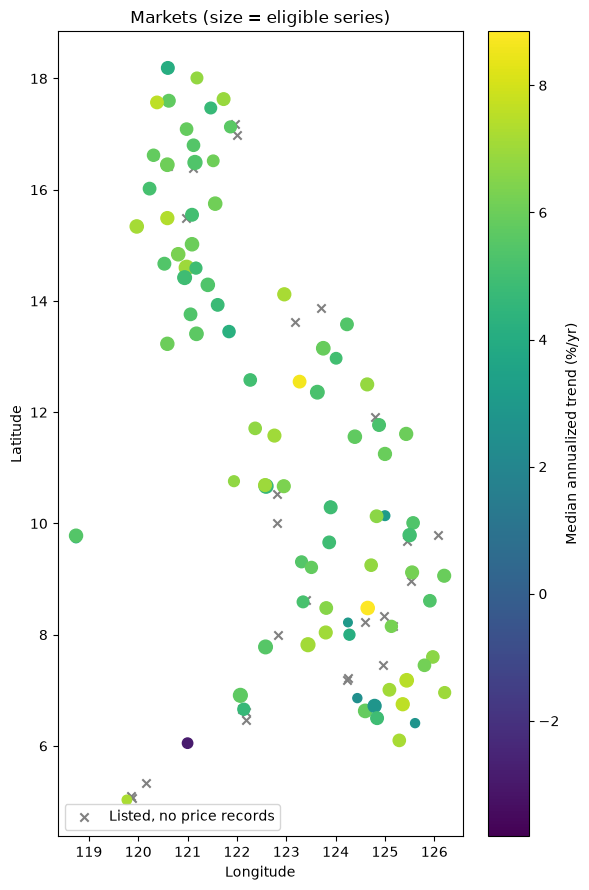

In [4]:
nop = markets_file[~markets_file["market_id"].isin(retail["market_id"])]
print("Listed markets without price records:", len(nop), "of", len(markets_file))
print(nop.groupby("admin1").size().sort_values(ascending=False).to_dict())
nop.to_csv(TAB / "09B_markets_without_prices.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 9))
ax.scatter(nop["longitude"], nop["latitude"], marker="x", color="grey", label="Listed, no price records")
sc = ax.scatter(mk["longitude"], mk["latitude"], c=mk["median_trend_pct_yr"],
                s=mk["eligible_series"].clip(lower=1) * 2 + 20, cmap="viridis")
plt.colorbar(sc, label="Median annualized trend (%/yr)")
ax.legend(loc="lower left"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Markets (size = eligible series)")
plt.tight_layout(); plt.savefig(FIG / "09B_market_map.png", dpi=150); plt.show()